In [73]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict, Annotated
from dotenv import load_dotenv
from pydantic import BaseModel, Field
import operator


In [74]:
load_dotenv()

True

In [75]:
llm = ChatGoogleGenerativeAI(
    model = "gemini-2.5-flash-lite"
)

In [76]:
class EvaluationSchema(BaseModel):
    feedback: str = Field(description='Detailed feedback for the eassy')
    score: int = Field(description='Score out of 10', gt=0, le=10)

In [77]:
structured_model = llm.with_structured_output(EvaluationSchema)

In [78]:
essay = """
Rise of AI in Agriculture
Artificial Intelligence (AI) is transforming the agriculture industry by making farming smarter, faster, and more efficient. Traditional farming methods often require a lot of time, hard work, and resources. With the help of AI, farmers can now improve crop production and manage their farms more effectively.

AI technologies such as drones, smart sensors, and machine learning help farmers monitor crops, detect diseases, and identify harmful insects. AI-powered machines can also analyze soil conditions and weather forecasts to help farmers decide when to plant seeds, apply fertilizers, and harvest crops.

Another major benefit of AI in agriculture is saving water and reducing waste. Smart irrigation systems provide water to crops only when needed. This helps farmers reduce costs and protect natural resources. AI can also increase food production and support farmers in meeting the growing demand for food.

However, AI in agriculture also has some challenges, including high costs, limited technical knowledge, and lack of access to modern technology in rural areas.

In conclusion, the rise of AI in agriculture is creating a new future for farming. It makes agriculture more productive, sustainable, and intelligent. With proper use of AI, farmers can grow better crops and contribute to a stronger food supply for the world.
"""

In [64]:
prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {essay}'

structured_model.invoke(prompt).feedback

"The essay provides a clear and concise overview of the impact of AI in agriculture. It effectively highlights the benefits, such as increased efficiency, improved crop management, and resource conservation, as well as acknowledges the challenges, like cost and accessibility. The language is accessible and easy to understand, with a logical flow from introduction to conclusion. The essay could be further enhanced by providing specific examples or statistics to support the claims made about AI's effectiveness."

In [79]:
#define State
class EssayState(TypedDict):
    essay: str
    lang_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    individual_score: Annotated[list[int], operator.add]
    avg_score: float


In [80]:
def evaluate_language(state: EssayState):

    prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)

    return {'lang_feedback': [output.feedback], 'individual_score': [output.score]}



In [81]:
def evaluate_analysis(state: EssayState):

    prompt = f'Evaluate the depth of analysis of the following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)

    return {'analysis_feedback': [output.feedback], 'individual_score': [output.score]}



In [82]:
def evaluate_thought(state: EssayState):

    prompt = f'Evaluate the clarity of thought of the following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)

    return {'clarity_feedback': [output.feedback], 'individual_score': [output.score]}



In [83]:
def finla_evaluation(state: EssayState):

    # summary feedback

    prompt = f'Based on the following feedbacks create a summarized feedback \n language feedback - {state["lang_feedback"]} \n depth of analysis feedback - {state['analysis_feedback']} \n clarity of thought feedback - {state['clarity_feedback']}'

    overall_feedback = llm.invoke(prompt).content



    # avg calculation
    avg_score = sum(state['individual_score'])/len(state['individual_score']) 

    return {'overall_feedback': overall_feedback, 'avg_score': avg_score}


In [84]:
#Build Graph 
graph = StateGraph(EssayState)


#Add Nodes
graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_analysis', evaluate_analysis)
graph.add_node('evaluate_thought', evaluate_thought)
graph.add_node('finla_evaluation', finla_evaluation)



#Add Edges
graph.add_edge(START, 'evaluate_language')
graph.add_edge(START, 'evaluate_analysis')
graph.add_edge(START, 'evaluate_thought')

graph.add_edge('evaluate_language', 'finla_evaluation')
graph.add_edge('evaluate_analysis', 'finla_evaluation')
graph.add_edge('evaluate_thought', 'finla_evaluation')

graph.add_edge('finla_evaluation', END)

workflow = graph.compile()


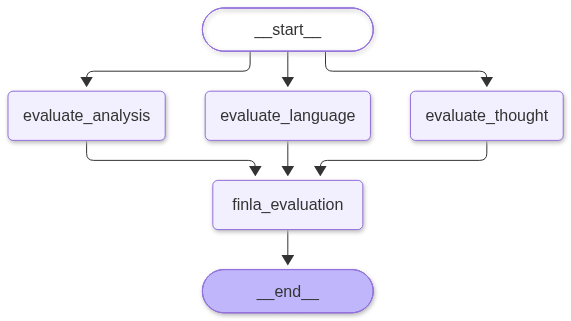

In [85]:
workflow

In [86]:
intail_state = {
    'essay': essay
}

workflow.invoke(intail_state)

{'essay': '\nRise of AI in Agriculture\nArtificial Intelligence (AI) is transforming the agriculture industry by making farming smarter, faster, and more efficient. Traditional farming methods often require a lot of time, hard work, and resources. With the help of AI, farmers can now improve crop production and manage their farms more effectively.\n\nAI technologies such as drones, smart sensors, and machine learning help farmers monitor crops, detect diseases, and identify harmful insects. AI-powered machines can also analyze soil conditions and weather forecasts to help farmers decide when to plant seeds, apply fertilizers, and harvest crops.\n\nAnother major benefit of AI in agriculture is saving water and reducing waste. Smart irrigation systems provide water to crops only when needed. This helps farmers reduce costs and protect natural resources. AI can also increase food production and support farmers in meeting the growing demand for food.\n\nHowever, AI in agriculture also has 